# Financial distress prediction for Vietnamese listed companies with CatBoost

Code for my Finance bachelor's thesis at UEH (2025). See the repository README for the summary and results.

**Data:** place `company_info.csv` and `financial_statement.csv` in the `data/` folder (see `data/README.md`). Comments and column names are in Vietnamese, as in the original thesis.


# Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time, psutil, os

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier, Pool

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score, RocCurveDisplay
from sklearn.inspection import PartialDependenceDisplay, partial_dependence
from skopt import BayesSearchCV
from sklearn.pipeline import Pipeline
from skopt.space import Real, Integer, Categorical

In [2]:
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
pd.set_option('display.max_colwidth', None)  # Hiển thị toàn bộ nội dung của từng ô
pd.set_option('display.expand_frame_repr', False)  # Tránh pandas cắt dòng

# Import data

In [3]:
# Dữ liệu về thông tin công ty
company_info = pd.read_csv('data/company_info.csv')
company_info.head(3)

,symbol,type,exchange,organ_name_x,icb_name2
0,YTC,STOCK,UPCOM,Công ty Cổ phần Xuất nhập khẩu Y tế Thành phố Hồ Chí Minh,Y tế
1,YEG,STOCK,HSX,Công ty Cổ phần Tập đoàn Yeah1,Truyền thông
2,YBM,STOCK,HSX,Công ty Cổ phần Khoáng sản Công nghiệp Yên Bái,Tài nguyên Cơ bản


In [4]:
# Dữ liệu về báo cáo tài chính
financial_statement = pd.read_csv('data/financial_statement.csv')
financial_statement.head(3)

,mã_ck,sàn,năm,Tài sản ngắn hạn,Trả trước cho người bán ngắn hạn,Hàng tồn kho (sau trừ dự phòng),Phải thu về cho vay ngắn hạn,Hàng tồn kho,Phải thu về cho vay dài hạn,Cổ phiếu phổ thông có quyền biểu quyết,...,LNST công ty mẹ không kiểm soát,LNST công ty mẹ,Lãi cơ bản trên cổ phiếu,Doanh thu thuần về bán hàng và cung cấp dịch vụ,Giá vốn hàng bán,Lợi nhuận gộp về bán hàng và cung cấp dịch vụ,Doanh thu hoạt động tài chính,Chi phí tài chính,Chi phí lãi vay.1,Chi phí bán hàng
0,YEG,HSX,2024,1.482480e+12,3.495630e+11,3.566820e+10,3.296910e+11,3.566820e+10,3.656928e+10,1.370010e+12,...,-2.250795e+08,1.269960e+11,927.0,1.006910e+12,-8.631170e+11,1.437970e+11,1.794570e+11,-3.667877e+10,-3.082151e+10,-2.592837e+10
1,YEG,HSX,2023,9.476400e+11,8.095766e+10,2.916861e+10,2.663340e+11,6.372433e+10,4.432958e+10,1.313530e+12,...,-3.397488e+08,2.685871e+10,565.0,4.116670e+11,-2.964810e+11,1.151860e+11,4.358640e+10,-2.348242e+10,-2.150500e+10,-1.426050e+10
2,YEG,HSX,2022,6.231590e+11,8.200514e+10,1.551100e+10,1.644330e+11,7.546702e+10,1.190000e+11,3.128000e+11,...,1.398687e+10,1.090399e+10,349.0,3.141240e+11,-2.096460e+11,1.044790e+11,4.734039e+10,-9.021747e+09,-6.906877e+09,-2.065875e+10


In [5]:
# Gộp 2 dataset
official_df_raw = pd.merge(company_info, financial_statement, left_on="symbol", right_on="mã_ck", how="left")

# Xóa các cột không cần thiết
official_df_raw.drop(columns=['symbol', 'type', 'exchange', 'organ_name_x'], inplace=True)

# Đổi tên cột
official_df_raw.rename(columns={'icb_name2': 'ngành'}, inplace=True)

# Chuyển đổi cột 'năm' sang kiểu int
official_df_raw['năm'] = pd.to_numeric(official_df_raw['năm'], errors='coerce').astype('Int64')

# Lọc dữ liệu từ 2014 đến 2023
official_df_raw = official_df_raw[(official_df_raw['năm'] >= 2014) & (official_df_raw['năm'] <= 2023)]

# Sắp xếp dữ liệu theo 'mã_ck' và 'năm'
official_df_raw.sort_values(by=['mã_ck', 'năm'], inplace=True)

# Reset index
official_df_raw.reset_index(drop=True, inplace=True)

# Chỉ lấy mã_ck có dữ liệu từ 3 năm trở lên ---
## Đếm số lượng năm dữ liệu cho mỗi mã_ck
year_count = official_df_raw.groupby('mã_ck')['năm'].nunique()

## Lọc ra các mã_ck có số lượng năm dữ liệu từ 3 trở lên
valid_codes = year_count[year_count >= 3].index

## Giữ lại các dòng dữ liệu của các mã_ck này
official_df_raw = official_df_raw[official_df_raw['mã_ck'].isin(valid_codes)]

official_df_raw.head(3)

,ngành,mã_ck,sàn,năm,Tài sản ngắn hạn,Trả trước cho người bán ngắn hạn,Hàng tồn kho (sau trừ dự phòng),Phải thu về cho vay ngắn hạn,Hàng tồn kho,Phải thu về cho vay dài hạn,...,LNST công ty mẹ không kiểm soát,LNST công ty mẹ,Lãi cơ bản trên cổ phiếu,Doanh thu thuần về bán hàng và cung cấp dịch vụ,Giá vốn hàng bán,Lợi nhuận gộp về bán hàng và cung cấp dịch vụ,Doanh thu hoạt động tài chính,Chi phí tài chính,Chi phí lãi vay.1,Chi phí bán hàng
0,Hàng cá nhân & Gia dụng,A32,UPCOM,2016,3.432790e+11,3.989892e+09,1.209140e+11,0.0,1.251150e+11,0.0,...,0.0,3.647336e+10,5364.0,6.292590e+11,-5.636140e+11,6.564503e+10,1.565139e+10,-665605942.0,0.0,-6.437314e+09
1,Hàng cá nhân & Gia dụng,A32,UPCOM,2017,3.741270e+11,1.821931e+09,1.304410e+11,0.0,1.342160e+11,0.0,...,0.0,3.544302e+10,5212.0,6.118210e+11,-5.462590e+11,6.556200e+10,1.360638e+10,-512163234.0,0.0,-6.871194e+09
2,Hàng cá nhân & Gia dụng,A32,UPCOM,2018,3.358630e+11,5.944384e+09,1.643550e+11,0.0,1.699700e+11,0.0,...,0.0,4.309588e+10,6338.0,6.461950e+11,-5.837470e+11,6.244782e+10,1.440583e+10,-577387667.0,0.0,-5.863308e+09


In [6]:
official_df_raw.to_csv('official_df_raw.csv')

In [7]:
official_df_raw['mã_ck'].nunique()

1480

In [8]:
# Lọc các cột cần thiết
firm_info_column = ['mã_ck', 'sàn', 'năm', 'ngành'] 
                     
bs_column = ['Tài sản ngắn hạn', 'Tiền và tương đương tiền', 'Các khoản đầu tư tài chính ngắn hạn', 'Các khoản phải thu ngắn hạn', 'Hàng tồn kho', 'Tài sản ngắn hạn khác',
             'Tài sản dài hạn', 'Các khoản phải thu dài hạn', 'Tài sản cố định', 'Bất động sản đầu tư',  'Đầu tư tài chính dài hạn', 'Tài sản dài hạn khác',
             'Tổng cộng tài sản', 
             'Nợ phải trả', 'Nợ ngắn hạn', 'Nợ dài hạn', 
             'Vốn chủ sở hữu (total)', 'Vốn chủ sở hữu', 'Lợi nhuận sau thuế chưa phân phối', 'Nguồn kinh phí và quỹ khác', 
             'Tổng cộng nguồn vốn']
                    
is_column = ['Doanh thu bán hàng và cung cấp dịch vụ',
             'Các khoản giảm trừ doanh thu',
             'Doanh thu thuần về bán hàng và cung cấp dịch vụ',
             'Giá vốn hàng bán',
             'Lợi nhuận gộp về bán hàng và cung cấp dịch vụ',
             'Doanh thu hoạt động tài chính',
             'Chi phí tài chính',
             'Chi phí lãi vay',
             'Lãi lỗ trong công ty liên doanh, liên kết',
             'Chi phí bán hàng',
             'Chi phí quản lý DN',
             'Lợi nhuận thuần từ hoạt động kinh doanh',
             'Thu nhập khác',
             'Chi phí khác',
             'Lợi nhuận khác',
             'Tổng lợi nhuận kế toán trước thuế',
             'Chi phí thuế TNDN hiện hành',
             'Chi phí thuế TNDN hoãn lại',
             'Lợi nhuận sau thuế TNDN',
             'LNST công ty mẹ']

cf_column = ['Lưu chuyển tiền thuần từ hoạt động kinh doanh',
             'Lưu chuyển tiền thuần từ hoạt động đầu tư',
             'Lưu chuyển tiền thuần từ hoạt động tài chính',
             'Lưu chuyển tiền thuần trong kỳ',
             'Tiền và tương đương tiền đầu kỳ',
             'Tiền và tương đương tiền cuối kỳ',
             'Khấu hao TSCĐ và BĐSĐT']

selected_columns = firm_info_column + bs_column + is_column + cf_column
official_df = official_df_raw[selected_columns].copy()
official_df.fillna(0, inplace=True)
official_df.head(3)

,mã_ck,sàn,năm,ngành,Tài sản ngắn hạn,Tiền và tương đương tiền,Các khoản đầu tư tài chính ngắn hạn,Các khoản phải thu ngắn hạn,Hàng tồn kho,Tài sản ngắn hạn khác,...,Chi phí thuế TNDN hoãn lại,Lợi nhuận sau thuế TNDN,LNST công ty mẹ,Lưu chuyển tiền thuần từ hoạt động kinh doanh,Lưu chuyển tiền thuần từ hoạt động đầu tư,Lưu chuyển tiền thuần từ hoạt động tài chính,Lưu chuyển tiền thuần trong kỳ,Tiền và tương đương tiền đầu kỳ,Tiền và tương đương tiền cuối kỳ,Khấu hao TSCĐ và BĐSĐT
0,A32,UPCOM,2016,Hàng cá nhân & Gia dụng,3.432790e+11,1.397740e+11,0.0,7.603621e+10,1.251150e+11,6.555357e+09,...,533338454.0,3.647336e+10,3.647336e+10,-3.127942e+10,-8.319863e+09,-9.400540e+10,-1.336050e+11,2.733780e+11,1.397740e+11,0.0
1,A32,UPCOM,2017,Hàng cá nhân & Gia dụng,3.741270e+11,1.456580e+11,0.0,9.794456e+10,1.342160e+11,8.285559e+07,...,0.0,3.544302e+10,3.544302e+10,-6.679452e+09,-2.375775e+09,1.494000e+10,5.884773e+09,1.397740e+11,1.456580e+11,0.0
2,A32,UPCOM,2018,Hàng cá nhân & Gia dụng,3.358630e+11,5.829081e+10,0.0,1.121030e+11,1.699700e+11,1.114031e+09,...,0.0,4.309588e+10,4.309588e+10,5.224003e+10,3.452162e+09,-1.430600e+11,-8.736751e+10,1.456580e+11,5.829081e+10,0.0


# Preprocessing data

## Tính toán các chỉ số

In [9]:
# Hàm tính chỉ số tài chính với kiểm tra mẫu số
def calculate_ratio(numerator, denominator):
    return np.where(denominator == 0, np.nan, numerator / denominator)

# Tạo df rỗng để lưu các chỉ số
financial_ratios = pd.DataFrame()

# Tính nhóm chỉ số Khả năng sinh lợi (Profitability Ratios)
financial_ratios['ROE'] = calculate_ratio(official_df['Lợi nhuận sau thuế TNDN'], official_df['Vốn chủ sở hữu (total)'])
financial_ratios['ROA'] = calculate_ratio(official_df['Lợi nhuận sau thuế TNDN'], official_df['Tổng cộng tài sản'])
financial_ratios['Biên lợi nhuận gộp'] = calculate_ratio(official_df['Lợi nhuận gộp về bán hàng và cung cấp dịch vụ'],
                                                          official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ']) 
financial_ratios['Biên lợi nhuận ròng'] = calculate_ratio(official_df['Lợi nhuận sau thuế TNDN'],
                                                           official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ'])

# Tính nhóm chỉ số Thanh khoản (Liquidity Ratios)
financial_ratios['Tỷ số thanh toán hiện hành'] = calculate_ratio(official_df['Tài sản ngắn hạn'], official_df['Nợ ngắn hạn'])
financial_ratios['Tỷ số thanh toán nhanh'] = calculate_ratio(official_df['Tài sản ngắn hạn'] - official_df['Hàng tồn kho'], official_df['Nợ ngắn hạn'])
financial_ratios['Vòng quay các khoản phải thu'] = calculate_ratio(official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ'], official_df['Các khoản phải thu ngắn hạn'])
financial_ratios['CFO/nợ ngắn hạn'] = calculate_ratio(official_df['Lưu chuyển tiền thuần từ hoạt động kinh doanh'], official_df['Nợ ngắn hạn'])

# Tính nhóm chỉ số Đòn bẩy (Solvency Ratios)
financial_ratios['Nợ/VCSH'] = calculate_ratio(official_df['Nợ phải trả'], official_df['Vốn chủ sở hữu (total)'])
financial_ratios['Nợ/Tài sản'] = calculate_ratio(official_df['Nợ phải trả'], official_df['Tổng cộng tài sản'])
financial_ratios['CFO/tổng nợ'] = calculate_ratio(official_df['Lưu chuyển tiền thuần từ hoạt động kinh doanh'], official_df['Nợ phải trả'])
financial_ratios['CFO/nợ dài hạn'] = calculate_ratio(official_df['Lưu chuyển tiền thuần từ hoạt động kinh doanh'], official_df['Nợ dài hạn'])

# Tính nhóm chỉ số Hiệu quả hoạt động (Activity Ratios)
financial_ratios['Vòng quay tổng tài sản'] = calculate_ratio(official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ'], official_df['Tổng cộng tài sản'])
financial_ratios['Vòng quay tài sản cố định'] = calculate_ratio(official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ'], official_df['Tài sản cố định'])
financial_ratios['Vòng quay vốn lưu động'] = calculate_ratio(official_df['Doanh thu thuần về bán hàng và cung cấp dịch vụ'], official_df['Tài sản ngắn hạn'] - official_df['Nợ ngắn hạn'])

# Tính nhóm chỉ số Tăng trưởng (Growth Ratios)
financial_ratios['Tăng trưởng trong doanh thu'] = official_df.groupby('mã_ck')['Doanh thu thuần về bán hàng và cung cấp dịch vụ'].pct_change()
financial_ratios['Tăng trưởng trong lợi nhuận ròng'] = official_df.groupby('mã_ck')['Lợi nhuận sau thuế TNDN'].pct_change()
financial_ratios['Tăng trưởng trong tài sản'] = official_df['Tổng cộng tài sản'].pct_change()
financial_ratios['Tăng trưởng trong thu nhập hoạt động'] = official_df['Lợi nhuận thuần từ hoạt động kinh doanh'].pct_change()

# Reset index để đảm bảo index khớp nhau
official_df = official_df.reset_index(drop=True)
financial_ratios = financial_ratios.reset_index(drop=True)

# Kết hợp hai DataFrame
df = pd.concat([official_df, financial_ratios], axis=1)
df.head(3)

,mã_ck,sàn,năm,ngành,Tài sản ngắn hạn,Tiền và tương đương tiền,Các khoản đầu tư tài chính ngắn hạn,Các khoản phải thu ngắn hạn,Hàng tồn kho,Tài sản ngắn hạn khác,...,Nợ/Tài sản,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
0,A32,UPCOM,2016,Hàng cá nhân & Gia dụng,3.432790e+11,1.397740e+11,0.0,7.603621e+10,1.251150e+11,6.555357e+09,...,0.648602,-0.103711,-12.875483,1.353231,5.779912,14.267294,NaN,NaN,NaN,NaN
1,A32,UPCOM,2017,Hàng cá nhân & Gia dụng,3.741270e+11,1.456580e+11,0.0,9.794456e+10,1.342160e+11,8.285559e+07,...,0.648132,-0.020571,-2.749449,1.221219,5.599013,11.800509,-0.027712,-0.028249,0.077391,-0.024427
2,A32,UPCOM,2018,Hàng cá nhân & Gia dụng,3.358630e+11,5.829081e+10,0.0,1.121030e+11,1.699700e+11,1.114031e+09,...,0.571684,0.194904,21.503456,1.378282,5.309257,9.196803,0.056183,0.215920,-0.064175,0.233866


## Xác định công ty không kiệt quệ (0) và kiệt quệ (1)

In [10]:
# --- Bước 1: Xác định các mã bị kiệt quệ ---
# a. Xác định các mã có lợi nhuận âm
# Xét từ 2015
df = df[df['năm'] >= 2015]

df['LNST_TNDN_neg'] = df['Lợi nhuận sau thuế TNDN'] < 0

# b. Tính consecutive_neg bằng apply() và rolling()
# Sắp xếp lại DataFrame trước khi rolling()
df = df.sort_values(by=['mã_ck', 'năm'])

# Hàm tính consecutive_neg cho từng nhóm
def calc_consecutive_neg(group):
    rolling_sum = group['LNST_TNDN_neg'].rolling(window=3, min_periods=3).sum()
    return (rolling_sum == 3).astype(int)

# Áp dụng trên từng nhóm
df['consecutive_neg'] = df.groupby('mã_ck', group_keys=False).apply(calc_consecutive_neg)

# Đảm bảo không có NaN và chuyển về kiểu int
df['consecutive_neg'] = df['consecutive_neg'].fillna(0).astype(int)

# c. Xác định các mã bị kiệt quệ
negative_profit_codes = df[df['consecutive_neg'] == 1]['mã_ck']
negative_equity_codes = df[df['Vốn chủ sở hữu (total)'] < 0]['mã_ck']
final_codes = sorted(pd.concat([negative_profit_codes, negative_equity_codes]).unique())

# d. Tạo cột kiệt_quệ (0 và 1)
df['kiệt_quệ'] = df['mã_ck'].apply(lambda x: 1 if x in final_codes else 0)

df.head(3)

,mã_ck,sàn,năm,ngành,Tài sản ngắn hạn,Tiền và tương đương tiền,Các khoản đầu tư tài chính ngắn hạn,Các khoản phải thu ngắn hạn,Hàng tồn kho,Tài sản ngắn hạn khác,...,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động,LNST_TNDN_neg,consecutive_neg,kiệt_quệ
0,A32,UPCOM,2016,Hàng cá nhân & Gia dụng,3.432790e+11,1.397740e+11,0.0,7.603621e+10,1.251150e+11,6.555357e+09,...,1.353231,5.779912,14.267294,NaN,NaN,NaN,NaN,False,0,0
1,A32,UPCOM,2017,Hàng cá nhân & Gia dụng,3.741270e+11,1.456580e+11,0.0,9.794456e+10,1.342160e+11,8.285559e+07,...,1.221219,5.599013,11.800509,-0.027712,-0.028249,0.077391,-0.024427,False,0,0
2,A32,UPCOM,2018,Hàng cá nhân & Gia dụng,3.358630e+11,5.829081e+10,0.0,1.121030e+11,1.699700e+11,1.114031e+09,...,1.378282,5.309257,9.196803,0.056183,0.215920,-0.064175,0.233866,False,0,0


In [11]:
# --- Bước 2: Xác định năm sự kiện (event year) ---
# a. Công ty kiệt quệ: Năm sự kiện là năm cuối trong chuỗi 3 năm liên tiếp lợi nhuận âm
event_years_distressed = (df[(df['kiệt_quệ'] == 1) & (df['consecutive_neg'] == 1)]
    .groupby('mã_ck')['năm']
    .max()
    .reset_index(name='event_year')
)

# b. Công ty không kiệt quệ: Năm sự kiện là năm gần nhất có dữ liệu
event_years_non_distressed = (df[df['kiệt_quệ'] == 0]
    .groupby('mã_ck')['năm']
    .max()
    .reset_index(name='event_year')
)

# c. Kết hợp năm sự kiện của cả hai nhóm
event_years = pd.concat([event_years_distressed, event_years_non_distressed])
df = df.merge(event_years, on='mã_ck', how='left')

# --- Bước 3: Tạo cột 'years_before_event' để tính khoảng cách từ năm hiện tại đến năm sự kiện ---
df['years_before_event'] = df['event_year'] - df['năm']

# --- Bước 4: Lấy dữ liệu ---
# a. Dữ liệu cho công ty kiệt quệ: 3 năm trước năm sự kiện
distressed_data = df[(df['kiệt_quệ'] == 1) & (df['years_before_event'].between(1, 3))].copy()

# Gán nhãn "3-year", "2-year", "1-year" dựa trên khoảng cách
distressed_data['label'] = distressed_data['years_before_event'].map({3: '3-year', 2: '2-year', 1: '1-year'})

# b. Dữ liệu cho công ty không kiệt quệ: 3 năm gần nhất
non_distressed_data = (df[df['kiệt_quệ'] == 0]
    .sort_values(by=['mã_ck', 'năm'], ascending=[True, False])  # Sắp xếp mã CK tăng dần, năm giảm dần
    .groupby('mã_ck')
    .head(3)  # Lấy 3 năm gần nhất
    .copy()
)

# Gán nhãn "3-year", "2-year", "1-year" theo thứ tự năm giảm dần
non_distressed_data['label'] = (
    non_distressed_data.groupby('mã_ck')['năm']
    .rank(method='first', ascending=False)  # Đánh số theo thứ tự giảm dần của năm
    .map({1: '1-year', 2: '2-year', 3: '3-year'})  # Chuyển đổi thành nhãn
)

# --- Bước 5: Kết hợp dữ liệu và sắp xếp ---
filtered_df = pd.concat([distressed_data, non_distressed_data])
filtered_df = filtered_df.sort_values(by=['mã_ck', 'năm'])

# Hiển thị kết quả
filtered_df[['mã_ck', 'năm', 'label', 'kiệt_quệ']]

# --- Bước 6: Lọc các cột cần thiết ---
columns_to_keep = ['mã_ck', 'sàn', 'năm', 'ngành', 'kiệt_quệ', 'label', 'ROE', 'ROA',
       'Biên lợi nhuận gộp', 'Biên lợi nhuận ròng',
       'Tỷ số thanh toán hiện hành', 'Tỷ số thanh toán nhanh',
       'CFO/nợ ngắn hạn', 'Nợ/VCSH', 'Nợ/Tài sản',
       'CFO/tổng nợ', 'CFO/nợ dài hạn',
       'Vòng quay các khoản phải thu', 'Vòng quay tổng tài sản', 'Vòng quay tài sản cố định',
       'Vòng quay vốn lưu động', 'Tăng trưởng trong doanh thu',
       'Tăng trưởng trong lợi nhuận ròng', 'Tăng trưởng trong tài sản',
       'Tăng trưởng trong thu nhập hoạt động'
]
final_df_1 = filtered_df[columns_to_keep]

# Hiển thị DataFrame cuối cùng
final_df_1.head(3)

,mã_ck,sàn,năm,ngành,kiệt_quệ,label,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,...,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
5,A32,UPCOM,2021,Hàng cá nhân & Gia dụng,0,3-year,0.145182,0.065532,0.109846,0.053233,...,0.230915,NaN,5.788097,1.231035,5.690374,5.794029,-0.107652,-0.178065,0.081582,-0.208005
6,A32,UPCOM,2022,Hàng cá nhân & Gia dụng,0,2-year,0.170226,0.066977,0.129816,0.050977,...,-0.047460,NaN,4.057722,1.313869,6.087803,8.602799,0.106333,0.059449,0.036584,0.083799
7,A32,UPCOM,2023,Hàng cá nhân & Gia dụng,0,1-year,0.178491,0.078406,0.115473,0.055077,...,0.040389,3.00509,4.545907,1.423563,6.356101,7.360712,0.000329,0.080794,-0.076752,0.089140


## Handling outliers 

### Check outliers

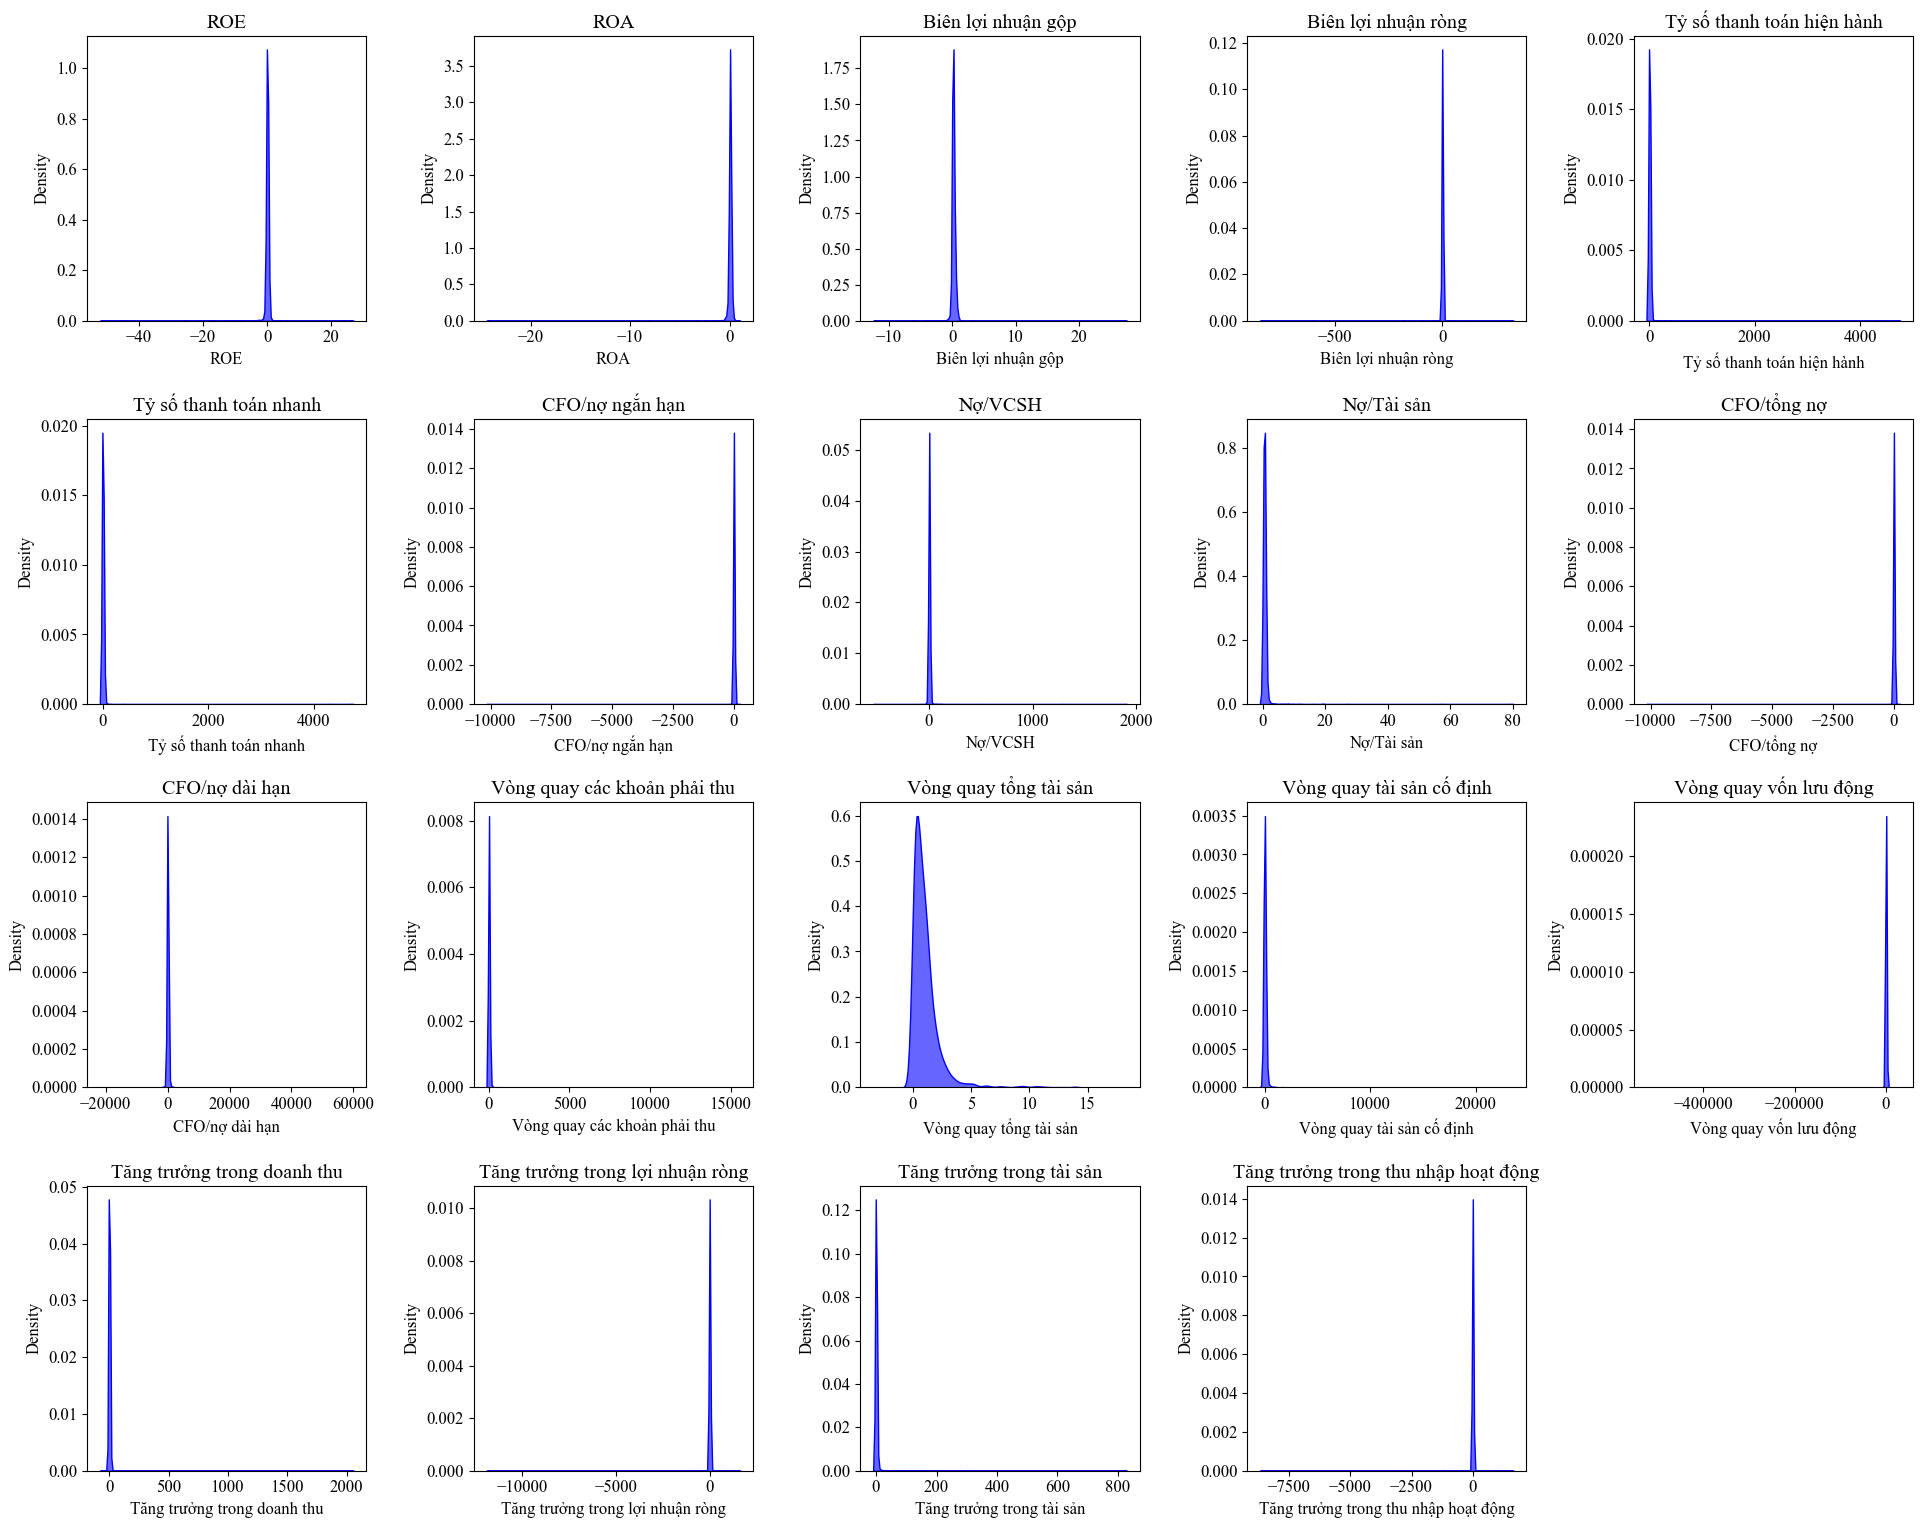

In [12]:
final_df = final_df_1.copy()

# Lấy danh sách các cột số, loại bỏ các cột không cần thiết
numeric_columns = final_df.select_dtypes(include=['int64', 'float64']).columns
numeric_columns = numeric_columns.drop(['kiệt_quệ', 'năm'])  # Loại bỏ cột 'kiệt_quệ' và 'năm'

# Tính toán số hàng và cột cho subplot
num_columns = len(numeric_columns)
num_rows = (num_columns + 4) // 5  # 5 cột mỗi hàng, điều chỉnh tùy ý
num_cols = min(num_columns, 5)  # Tối đa 5 cột mỗi hàng

# Tạo subplot
fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 4 * num_rows))
fig.tight_layout(pad=4.0)  # Điều chỉnh khoảng cách giữa các subplot

# Lặp qua từng cột và vẽ KDE plot
for i, column in enumerate(numeric_columns):
    row = i // num_cols
    col = i % num_cols
    ax = axes[row, col] if num_rows > 1 else axes[col]  # Xử lý trường hợp chỉ có 1 hàng
    sns.kdeplot(data=final_df, x=column, color='blue', fill=True, alpha=0.6, ax=ax)
    ax.set_title(f'{column}')
    ax.set_xlabel(column)
    ax.set_ylabel('Density')

# Ẩn các subplot không sử dụng (nếu có)
for i in range(num_columns, num_rows * num_cols):
    row = i // num_cols
    col = i % num_cols
    ax = axes[row, col] if num_rows > 1 else axes[col]
    ax.axis('off')  # Ẩn subplot không sử dụng

plt.show()

### Handling outliers

In [13]:
# Lọc các cột số
numeric_columns = final_df.select_dtypes(include=['int64', 'float64']).columns
numeric_columns = numeric_columns.drop(['kiệt_quệ', 'năm'])

# Hàm xử lý outlier bằng IQR
def replace_outliers_with_bounds(df, numeric_columns):
    for col in numeric_columns:
        # Tính Q1, Q3 và IQR
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        # Tính lower bound và upper bound
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        # Thay thế outlier bằng lower/upper bound (dùng .loc để tránh SettingWithCopyWarning)
        df.loc[df[col] < lower_bound, col] = lower_bound
        df.loc[df[col] > upper_bound, col] = upper_bound
    
    return df  # Trả về final_df đã được cập nhật

# Áp dụng hàm trực tiếp lên final_df
final_df = replace_outliers_with_bounds(final_df, numeric_columns)

# In kết quả
final_df.head(3)

,mã_ck,sàn,năm,ngành,kiệt_quệ,label,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,...,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
5,A32,UPCOM,2021,Hàng cá nhân & Gia dụng,0,3-year,0.145182,0.065532,0.109846,0.053233,...,0.230915,NaN,5.788097,1.231035,5.690374,5.794029,-0.107652,-0.178065,0.081582,-0.208005
6,A32,UPCOM,2022,Hàng cá nhân & Gia dụng,0,2-year,0.170226,0.066977,0.129816,0.050977,...,-0.047460,NaN,4.057722,1.313869,6.087803,8.602799,0.106333,0.059449,0.036584,0.083799
7,A32,UPCOM,2023,Hàng cá nhân & Gia dụng,0,1-year,0.178491,0.078406,0.115473,0.055077,...,0.040389,3.00509,4.545907,1.423563,6.356101,7.360712,0.000329,0.080794,-0.076752,0.089140


## Handling missing values & inf

### Checking missing values

In [14]:
final_df.isna().sum()

mã_ck                                     0
sàn                                       0
năm                                       0
ngành                                     0
kiệt_quệ                                  0
label                                     0
ROE                                       0
ROA                                       0
Biên lợi nhuận gộp                       47
Biên lợi nhuận ròng                      47
Tỷ số thanh toán hiện hành                0
Tỷ số thanh toán nhanh                    0
CFO/nợ ngắn hạn                           0
Nợ/VCSH                                   0
Nợ/Tài sản                                0
CFO/tổng nợ                               0
CFO/nợ dài hạn                          955
Vòng quay các khoản phải thu              2
Vòng quay tổng tài sản                    0
Vòng quay tài sản cố định                86
Vòng quay vốn lưu động                    0
Tăng trưởng trong doanh thu             621
Tăng trưởng trong lợi nhuận ròng

### Handling missing values

In [15]:
# Tạo bản sao trước khi thao tác
final_df = final_df.copy()

# Điền NaN bằng median của toàn bộ dataset
final_df[numeric_columns] = final_df[numeric_columns].fillna(final_df[numeric_columns].median(numeric_only=True))

# In kết quả
final_df.head(3)

,mã_ck,sàn,năm,ngành,kiệt_quệ,label,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,...,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
5,A32,UPCOM,2021,Hàng cá nhân & Gia dụng,0,3-year,0.145182,0.065532,0.109846,0.053233,...,0.230915,0.333563,5.788097,1.231035,5.690374,5.794029,-0.107652,-0.178065,0.081582,-0.208005
6,A32,UPCOM,2022,Hàng cá nhân & Gia dụng,0,2-year,0.170226,0.066977,0.129816,0.050977,...,-0.047460,0.333563,4.057722,1.313869,6.087803,8.602799,0.106333,0.059449,0.036584,0.083799
7,A32,UPCOM,2023,Hàng cá nhân & Gia dụng,0,1-year,0.178491,0.078406,0.115473,0.055077,...,0.040389,3.005090,4.545907,1.423563,6.356101,7.360712,0.000329,0.080794,-0.076752,0.089140


In [16]:
final_df.isna().sum()

mã_ck                                   0
sàn                                     0
năm                                     0
ngành                                   0
kiệt_quệ                                0
label                                   0
ROE                                     0
ROA                                     0
Biên lợi nhuận gộp                      0
Biên lợi nhuận ròng                     0
Tỷ số thanh toán hiện hành              0
Tỷ số thanh toán nhanh                  0
CFO/nợ ngắn hạn                         0
Nợ/VCSH                                 0
Nợ/Tài sản                              0
CFO/tổng nợ                             0
CFO/nợ dài hạn                          0
Vòng quay các khoản phải thu            0
Vòng quay tổng tài sản                  0
Vòng quay tài sản cố định               0
Vòng quay vốn lưu động                  0
Tăng trưởng trong doanh thu             0
Tăng trưởng trong lợi nhuận ròng        0
Tăng trưởng trong tài sản         

## Handling correlation

In [17]:
periods = ['1-year', '2-year', '3-year']

for period in periods:
    # Lọc dữ liệu
    period_data = final_df[final_df['label'] == period].drop(columns=['năm', 'kiệt_quệ'])

    # Tính ma trận tương quan
    corr = period_data.corr(numeric_only=True)
    
    print(f'correlation of {period}')
    display(corr)

correlation of 1-year


,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,CFO/nợ ngắn hạn,Nợ/VCSH,Nợ/Tài sản,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
ROE,1.000000,0.710609,0.310343,0.526707,0.113513,0.143034,0.315062,-0.332949,-0.025973,0.318860,0.216514,0.214733,0.250556,0.109000,0.151880,0.054259,0.011840,0.026223,0.025962
ROA,0.710609,1.000000,0.475044,0.776304,0.386305,0.396880,0.460055,-0.157201,-0.497288,0.472405,0.296979,0.256385,0.228234,0.086562,0.171598,0.040353,0.013825,0.020810,0.036283
Biên lợi nhuận gộp,0.310343,0.475044,1.000000,0.597954,0.235855,0.242533,0.309223,-0.159581,-0.281287,0.253872,0.121674,-0.044227,-0.288448,-0.182618,-0.106397,0.011939,-0.030817,0.007144,0.018058
Biên lợi nhuận ròng,0.526707,0.776304,0.597954,1.000000,0.419197,0.427507,0.364797,-0.159117,-0.476658,0.321450,0.145960,0.043075,-0.117831,-0.040270,0.008461,0.032139,-0.007337,0.029304,0.024954
Tỷ số thanh toán hiện hành,0.113513,0.386305,0.235855,0.419197,1.000000,0.930325,0.214980,-0.369869,-0.730900,0.222954,0.111654,-0.006925,-0.100378,0.064639,-0.084674,-0.023928,-0.038511,0.029243,-0.039255
Tỷ số thanh toán nhanh,0.143034,0.396880,0.242533,0.427507,0.930325,1.000000,0.251834,-0.374058,-0.704402,0.245367,0.110943,-0.049108,-0.119678,0.043184,-0.082543,-0.035085,-0.050667,0.015911,-0.033773
CFO/nợ ngắn hạn,0.315062,0.460055,0.309223,0.364797,0.214980,0.251834,1.000000,-0.192170,-0.289250,0.952938,0.474309,0.279820,0.069110,-0.102744,0.020425,0.018194,0.028474,0.015089,0.024074
Nợ/VCSH,-0.332949,-0.157201,-0.159581,-0.159117,-0.369869,-0.374058,-0.192170,1.000000,0.406831,-0.202916,-0.126662,-0.096342,0.115247,0.146693,0.158506,-0.009833,0.021589,-0.009319,0.015441
Nợ/Tài sản,-0.025973,-0.497288,-0.281287,-0.476658,-0.730900,-0.704402,-0.289250,0.406831,1.000000,-0.309682,-0.162338,-0.126247,0.060119,0.057340,0.035659,-0.001258,0.013990,-0.017730,0.012619
CFO/tổng nợ,0.318860,0.472405,0.253872,0.321450,0.222954,0.245367,0.952938,-0.202916,-0.309682,1.000000,0.561433,0.279411,0.139136,-0.047886,0.036137,0.021748,0.035332,0.005157,0.031327


correlation of 2-year


,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,CFO/nợ ngắn hạn,Nợ/VCSH,Nợ/Tài sản,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
ROE,1.000000,0.756842,0.377280,0.573566,0.079834,0.098404,0.326572,-0.234706,-0.014392,0.307293,0.165783,0.237278,0.236893,0.040036,0.110957,0.010844,0.073194,0.038419,0.080244
ROA,0.756842,1.000000,0.485041,0.761200,0.340758,0.343451,0.430795,-0.153775,-0.450854,0.427728,0.201263,0.292588,0.242658,0.045058,0.143767,0.011233,0.054719,0.034964,0.069399
Biên lợi nhuận gộp,0.377280,0.485041,1.000000,0.667878,0.224730,0.235831,0.365466,-0.184771,-0.249441,0.316676,0.138954,-0.012085,-0.276760,-0.196542,-0.134517,0.033044,0.022511,0.045245,0.049288
Biên lợi nhuận ròng,0.573566,0.761200,0.667878,1.000000,0.356403,0.363060,0.372793,-0.143864,-0.402635,0.315402,0.098202,0.067155,-0.127808,-0.089487,-0.021410,0.047291,0.079112,0.066538,0.088485
Tỷ số thanh toán hiện hành,0.079834,0.340758,0.224730,0.356403,1.000000,0.930695,0.176135,-0.379716,-0.727391,0.182948,0.011665,-0.011232,-0.090054,0.027953,-0.092075,0.032188,0.030987,0.022753,0.005380
Tỷ số thanh toán nhanh,0.098404,0.343451,0.235831,0.363060,0.930695,1.000000,0.222395,-0.379644,-0.695803,0.219665,0.033062,-0.076713,-0.130408,0.002784,-0.103328,0.035326,0.027289,0.025873,0.003019
CFO/nợ ngắn hạn,0.326572,0.430795,0.365466,0.372793,0.176135,0.222395,1.000000,-0.176286,-0.244728,0.952698,0.488763,0.310547,0.055892,-0.164659,-0.022498,-0.032383,0.052743,-0.007230,0.044873
Nợ/VCSH,-0.234706,-0.153775,-0.184771,-0.143864,-0.379716,-0.379644,-0.176286,1.000000,0.450861,-0.197400,-0.093055,-0.091666,0.128636,0.184768,0.148538,-0.025454,-0.018518,0.032390,-0.009004
Nợ/Tài sản,-0.014392,-0.450854,-0.249441,-0.402635,-0.727391,-0.695803,-0.244728,0.450861,1.000000,-0.271796,-0.084441,-0.146491,0.032748,0.067114,0.032293,-0.020310,-0.012772,-0.011037,-0.013216
CFO/tổng nợ,0.307293,0.427728,0.316676,0.315402,0.182948,0.219665,0.952698,-0.197400,-0.271796,1.000000,0.574019,0.314478,0.104341,-0.140189,-0.010380,-0.038262,0.039898,-0.016377,0.036776


correlation of 3-year


,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,CFO/nợ ngắn hạn,Nợ/VCSH,Nợ/Tài sản,CFO/tổng nợ,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
ROE,1.000000,0.743508,0.342355,0.515679,0.028995,0.030664,0.248199,-0.140567,0.058504,0.249876,0.144093,0.231432,0.252792,0.078995,0.118653,-0.001606,-0.068492,0.015639,-0.035039
ROA,0.743508,1.000000,0.468866,0.721645,0.312271,0.297258,0.365384,-0.151574,-0.416207,0.381858,0.199140,0.258646,0.231550,0.069004,0.131390,0.040979,-0.038921,0.016704,-0.012376
Biên lợi nhuận gộp,0.342355,0.468866,1.000000,0.672930,0.221562,0.230347,0.312749,-0.141790,-0.255740,0.260925,0.097406,-0.001306,-0.272922,-0.175747,-0.106893,0.018482,0.018491,0.031998,0.041071
Biên lợi nhuận ròng,0.515679,0.721645,0.672930,1.000000,0.357961,0.369892,0.291826,-0.134579,-0.386916,0.247633,0.091833,-0.017917,-0.224046,-0.085184,-0.066376,0.027981,0.000603,0.036629,0.051333
Tỷ số thanh toán hiện hành,0.028995,0.312271,0.221562,0.357961,1.000000,0.936333,0.107572,-0.407435,-0.713666,0.128686,0.062208,-0.051779,-0.122018,0.062579,-0.091348,0.011160,0.022109,-0.026473,0.036110
Tỷ số thanh toán nhanh,0.030664,0.297258,0.230347,0.369892,0.936333,1.000000,0.151476,-0.407335,-0.686287,0.157370,0.055006,-0.123713,-0.172914,0.024793,-0.112277,0.024591,0.022942,-0.024484,0.034997
CFO/nợ ngắn hạn,0.248199,0.365384,0.312749,0.291826,0.107572,0.151476,1.000000,-0.143726,-0.204580,0.946235,0.488367,0.262933,-0.009905,-0.179974,-0.037381,-0.002418,-0.019716,0.018493,0.012181
Nợ/VCSH,-0.140567,-0.151574,-0.141790,-0.134579,-0.407435,-0.407335,-0.143726,1.000000,0.552988,-0.162607,-0.082601,-0.102879,0.115746,0.176854,0.148743,0.003803,-0.000041,0.022146,-0.015568
Nợ/Tài sản,0.058504,-0.416207,-0.255740,-0.386916,-0.713666,-0.686287,-0.204580,0.552988,1.000000,-0.233346,-0.126278,-0.119855,0.071483,0.086161,0.061007,-0.016435,-0.040056,0.019229,-0.041836
CFO/tổng nợ,0.249876,0.381858,0.260925,0.247633,0.128686,0.157370,0.946235,-0.162607,-0.233346,1.000000,0.584731,0.267812,0.046935,-0.143535,-0.012620,-0.004131,-0.014482,0.006457,-0.002235


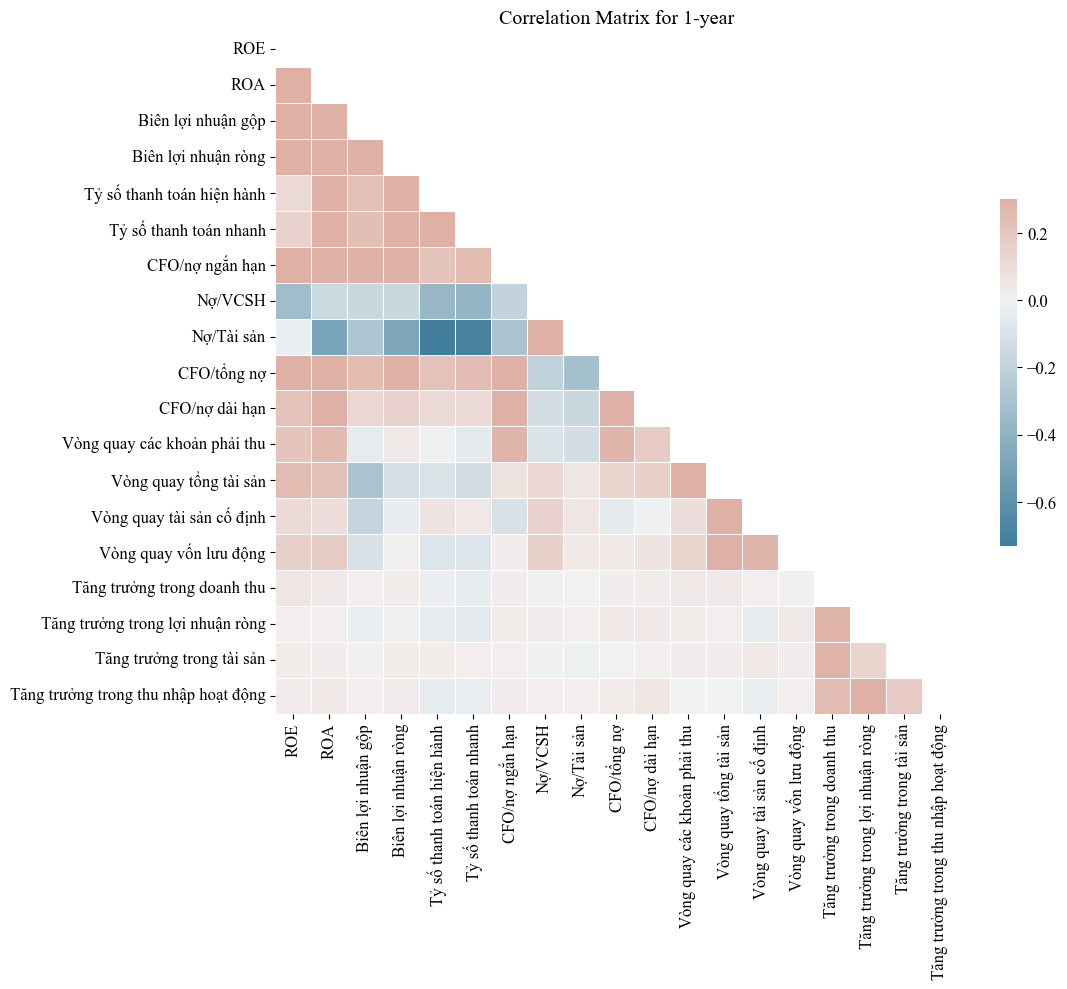

Các cặp tương quan cao trong nhóm 1-year:


,Feature 1,Feature 2,Correlation
95,CFO/nợ ngắn hạn,CFO/tổng nợ,0.952938
66,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,0.930325
19,ROA,Biên lợi nhuận ròng,0.776304
0,ROE,ROA,0.710609
82,Tỷ số thanh toán nhanh,Nợ/Tài sản,-0.704402
69,Tỷ số thanh toán hiện hành,Nợ/Tài sản,-0.730900


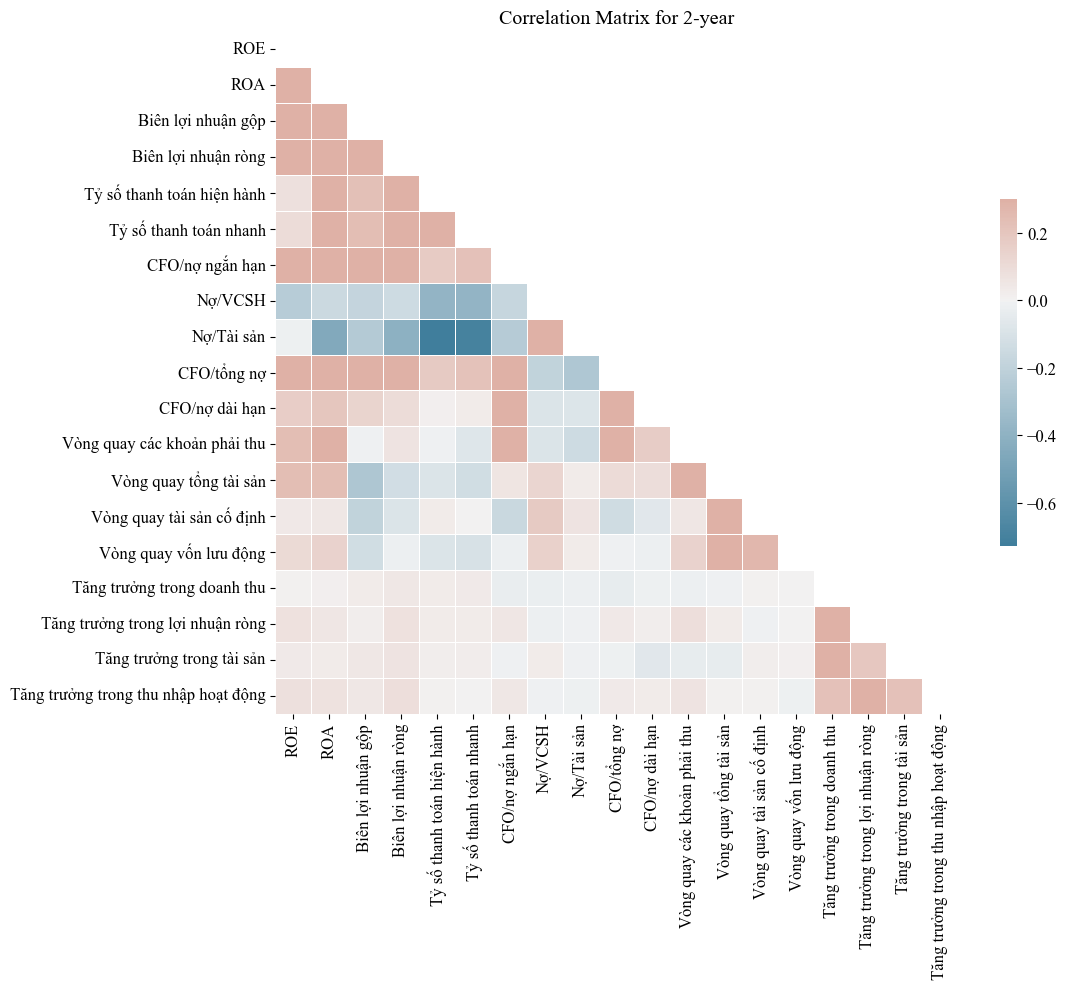

Các cặp tương quan cao trong nhóm 2-year:


,Feature 1,Feature 2,Correlation
95,CFO/nợ ngắn hạn,CFO/tổng nợ,0.952698
66,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,0.930695
19,ROA,Biên lợi nhuận ròng,0.761200
0,ROE,ROA,0.756842
69,Tỷ số thanh toán hiện hành,Nợ/Tài sản,-0.727391


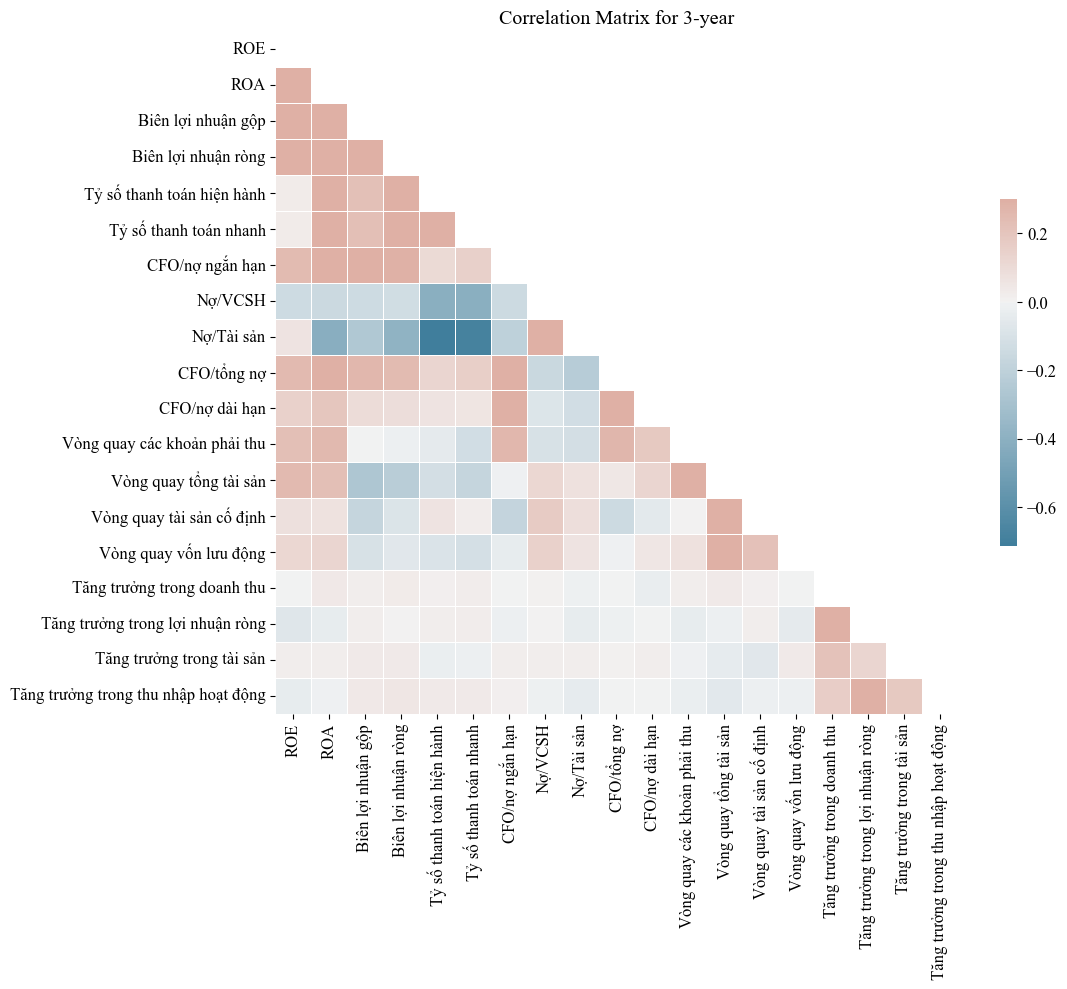

Các cặp tương quan cao trong nhóm 3-year:


,Feature 1,Feature 2,Correlation
95,CFO/nợ ngắn hạn,CFO/tổng nợ,0.946235
66,Tỷ số thanh toán hiện hành,Tỷ số thanh toán nhanh,0.936333
0,ROE,ROA,0.743508
19,ROA,Biên lợi nhuận ròng,0.721645
69,Tỷ số thanh toán hiện hành,Nợ/Tài sản,-0.713666


In [18]:
# Danh sách các nhóm cần vẽ heatmap
periods = ['1-year', '2-year', '3-year']

for period in periods:
    # Lọc dữ liệu
    period_data = final_df[final_df['label'] == period].drop(columns=['năm', 'kiệt_quệ'])

    # Tính ma trận tương quan
    corr = period_data.corr(numeric_only=True)

    # Vẽ heatmap
    plt.figure(figsize=(11, 9))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), 
                cmap=sns.diverging_palette(230, 20, as_cmap=True), 
                vmax=.3, center=0, square=True, linewidths=.5, cbar_kws={"shrink": .5})
    plt.title(f'Correlation Matrix for {period}')
    plt.savefig(f"{period}.png", dpi=300, bbox_inches='tight')
    plt.show()


    # Lọc và hiển thị các cặp tương quan cao
    high_corr_pairs = (
        corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
        .stack()
        .reset_index()
    )
    high_corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
    high_corr_pairs = high_corr_pairs[
        (high_corr_pairs['Correlation'].abs() >= 0.7)
    ].sort_values(by='Correlation', ascending=False)

    print(f"Các cặp tương quan cao trong nhóm {period}:")
    display(high_corr_pairs)

In [19]:
# Loại bỏ các cột do correlation cao
drop_columns = ['CFO/tổng nợ', 'Tỷ số thanh toán hiện hành']

# Cập nhật final_df và reset index
final_df = final_df.drop(columns=drop_columns, errors='ignore').reset_index(drop=True)

# Kiểm tra kết quả
final_df.head(3)

,mã_ck,sàn,năm,ngành,kiệt_quệ,label,ROE,ROA,Biên lợi nhuận gộp,Biên lợi nhuận ròng,...,Nợ/Tài sản,CFO/nợ dài hạn,Vòng quay các khoản phải thu,Vòng quay tổng tài sản,Vòng quay tài sản cố định,Vòng quay vốn lưu động,Tăng trưởng trong doanh thu,Tăng trưởng trong lợi nhuận ròng,Tăng trưởng trong tài sản,Tăng trưởng trong thu nhập hoạt động
0,A32,UPCOM,2021,Hàng cá nhân & Gia dụng,0,3-year,0.145182,0.065532,0.109846,0.053233,...,0.548625,0.333563,5.788097,1.231035,5.690374,5.794029,-0.107652,-0.178065,0.081582,-0.208005
1,A32,UPCOM,2022,Hàng cá nhân & Gia dụng,0,2-year,0.170226,0.066977,0.129816,0.050977,...,0.606543,0.333563,4.057722,1.313869,6.087803,8.602799,0.106333,0.059449,0.036584,0.083799
2,A32,UPCOM,2023,Hàng cá nhân & Gia dụng,0,1-year,0.178491,0.078406,0.115473,0.055077,...,0.560726,3.005090,4.545907,1.423563,6.356101,7.360712,0.000329,0.080794,-0.076752,0.089140


# Descriptive statistics

In [20]:
print(f"Số lượng công ty không kiệt quệ: {final_df[final_df['kiệt_quệ'] == 0]['mã_ck'].nunique()}")
print(f"% không kiệt quệ: {final_df[final_df['kiệt_quệ'] == 0]['mã_ck'].nunique() / final_df['mã_ck'].nunique()*100}")
print(f"Số lượng công ty không kiệt quệ: {final_df[final_df['kiệt_quệ'] == 1]['mã_ck'].nunique()}")
print(f"% kiệt quệ: {final_df[final_df['kiệt_quệ'] == 1]['mã_ck'].nunique() / final_df['mã_ck'].nunique()*100}")

Số lượng công ty không kiệt quệ: 1265
% không kiệt quệ: 86.94158075601375
Số lượng công ty không kiệt quệ: 190
% kiệt quệ: 13.058419243986256


In [21]:
# Tính số lượng công ty không kiệt quệ và kiệt quệ theo từng sàn
count_df = (
    final_df.groupby(['sàn', 'kiệt_quệ'])['mã_ck']
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# Đổi tên cột cho dễ hiểu
count_df.columns = ['sàn', 'số lượng không kiệt quệ', 'số lượng kiệt quệ']

# Tính tổng số công ty trên từng sàn
count_df['tổng số công ty'] = count_df['số lượng không kiệt quệ'] + count_df['số lượng kiệt quệ']

# Tính % kiệt quệ
count_df['% kiệt_quệ'] = (count_df['số lượng kiệt quệ'] / count_df['tổng số công ty'] * 100).round(2)

print("Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng sàn:")
count_df

Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng sàn:


,sàn,số lượng không kiệt quệ,số lượng kiệt quệ,tổng số công ty,% kiệt_quệ
0,HNX,290,1,291,0.34
1,HSX,345,3,348,0.86
2,UPCOM,630,186,816,22.79


In [22]:
# Tính số lượng công ty không kiệt quệ và kiệt quệ theo từng ngành
count_by_sector = (
    final_df.groupby(['ngành', 'kiệt_quệ'])['mã_ck']
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# Đổi tên cột cho dễ hiểu
count_by_sector.columns = ['ngành', 'số lượng không kiệt quệ', 'số lượng kiệt quệ']

# Tính tổng số công ty trong từng ngành
count_by_sector['tổng số công ty'] = count_by_sector['số lượng không kiệt quệ'] + count_by_sector['số lượng kiệt quệ']

# Tính % kiệt quệ
count_by_sector['% kiệt_quệ'] = (count_by_sector['số lượng kiệt quệ'] / count_by_sector['tổng số công ty'] * 100).round(2)

print("Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng ngành:")
count_by_sector.sort_values(by='% kiệt_quệ', ascending=False)

Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng ngành:


,ngành,số lượng không kiệt quệ,số lượng kiệt quệ,tổng số công ty,% kiệt_quệ
3,Du lịch và Giải trí,34,12,46,26.09
12,Xây dựng và Vật liệu,252,64,316,20.25
8,Thực phẩm và đồ uống,117,27,144,18.75
0,Bán lẻ,23,5,28,17.86
11,Viễn thông,6,1,7,14.29
6,Hàng cá nhân & Gia dụng,65,10,75,13.33
1,Bất động sản,109,16,125,12.80
5,Hàng & Dịch vụ Công nghiệp,216,28,244,11.48
2,Công nghệ Thông tin,26,3,29,10.34
13,Y tế,54,5,59,8.47


In [23]:
# Tính số lượng công ty không kiệt quệ và kiệt quệ theo từng thời gian
count_by_period = (
    final_df.groupby(['label', 'kiệt_quệ'])['mã_ck']
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

# Đổi tên cột cho dễ hiểu
count_by_period.columns = ['label', 'số lượng không kiệt quệ', 'số lượng kiệt quệ']

# Tính tổng số công ty trong từng thời gian
count_by_period['tổng số công ty'] = count_by_period['số lượng không kiệt quệ'] + count_by_period['số lượng kiệt quệ']

# Tính % kiệt quệ
count_by_period['% kiệt_quệ'] = (count_by_period['số lượng kiệt quệ'] / count_by_period['tổng số công ty'] * 100).round(2)

print("Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng thời gian:")
count_by_period

Thống kê số lượng công ty và tỷ lệ kiệt quệ theo từng thời gian:


,label,số lượng không kiệt quệ,số lượng kiệt quệ,tổng số công ty,% kiệt_quệ
0,1-year,1265,187,1452,12.88
1,2-year,1265,188,1453,12.94
2,3-year,1263,169,1432,11.80


In [24]:
# Phân chia thành hai nhóm
group_0 = final_df_1[final_df_1['kiệt_quệ'] == 0].drop(columns=['năm'])
group_1 = final_df_1[final_df_1['kiệt_quệ'] == 1].drop(columns=['năm'])

# Định nghĩa hàm get_stats
def get_stats(df):
    # Loại bỏ các cột không phải số
    df_numeric = df.select_dtypes(include=[np.number])
    
    # Thay thế inf và -inf bằng NaN
    df_numeric = df_numeric.replace([np.inf, -np.inf], np.nan)

    # Điền NaN bằng median của từng cột
    df_numeric = df_numeric.fillna(df_numeric.median(numeric_only=True))
    
    # Tính toán các thống kê mô tả
    stats_df = pd.DataFrame({
        'min': df_numeric.min(),
        'max': df_numeric.max(),
        'median': df_numeric.median(),
        'mean': df_numeric.mean(),
        'std': df_numeric.std()
    })
    
    # Format numbers to 3 decimal places
    stats_df = stats_df.applymap(lambda x: f"{x:,.3f}")
    
    return stats_df

# Tính toán thống kê mô tả cho từng nhóm
desc_stats_0 = get_stats(group_0)
desc_stats_1 = get_stats(group_1)

# Hiển thị kết quả
print("Thống kê mô tả nhóm an toàn (without handling)")
display(desc_stats_0)

print("\nThống kê mô tả nhóm kiệt quệ (without handling)")
display(desc_stats_1)

Thống kê mô tả nhóm an toàn (without handling)


,min,max,median,mean,std
kiệt_quệ,0.000,0.000,0.000,0.000,0.000
ROE,-43.877,23.553,0.077,0.056,0.928
ROA,-0.832,0.806,0.037,0.049,0.081
Biên lợi nhuận gộp,-12.041,3.177,0.154,0.199,0.289
Biên lợi nhuận ròng,-95.098,323.094,0.043,0.218,6.076
Tỷ số thanh toán hiện hành,0.034,"4,700.571",1.590,5.608,103.924
Tỷ số thanh toán nhanh,-0.187,"4,700.571",1.128,4.936,103.796
CFO/nợ ngắn hạn,"-10,082.819",178.669,0.114,-2.410,163.786
Nợ/VCSH,0.000,"1,891.872",0.835,2.277,31.542
Nợ/Tài sản,0.000,0.999,0.455,0.454,0.234



Thống kê mô tả nhóm kiệt quệ (without handling)


,min,max,median,mean,std
kiệt_quệ,1.000,1.000,1.000,1.000,0.000
ROE,-51.125,26.010,-0.034,-0.428,3.859
ROA,-24.205,0.681,-0.062,-0.219,1.206
Biên lợi nhuận gộp,-6.081,27.099,0.074,0.082,1.737
Biên lợi nhuận ròng,-842.954,42.209,-0.219,-3.758,45.310
Tỷ số thanh toán hiện hành,0.001,22.683,0.842,1.458,2.612
Tỷ số thanh toán nhanh,-0.032,22.679,0.471,1.065,2.277
CFO/nợ ngắn hạn,-166.134,7.457,0.005,-0.347,7.180
Nợ/VCSH,-519.021,"1,296.508",0.467,3.847,65.589
Nợ/Tài sản,0.007,79.281,0.743,1.564,4.840


In [25]:
# Phân chia thành hai nhóm
group_0 = final_df[final_df['kiệt_quệ'] == 0].drop(columns=['năm'])
group_1 = final_df[final_df['kiệt_quệ'] == 1].drop(columns=['năm'])

# Định nghĩa hàm get_stats
def get_stats(df):
    # Loại bỏ các cột không phải số
    df_numeric = df.select_dtypes(include=[np.number])
    
    # Thay thế inf và -inf bằng NaN
    df_numeric = df_numeric.replace([np.inf, -np.inf], np.nan)

    # Điền NaN bằng median của từng cột
    df_numeric = df_numeric.fillna(df_numeric.median(numeric_only=True))
    
    # Tính toán các thống kê mô tả
    stats_df = pd.DataFrame({
        'min': df_numeric.min(),
        'max': df_numeric.max(),
        'median': df_numeric.median(),
        'mean': df_numeric.mean(),
        'std': df_numeric.std()
    })
    
    # Format numbers to 3 decimal places
    stats_df = stats_df.applymap(lambda x: f"{x:,.3f}")
    
    return stats_df

# Tính toán thống kê mô tả cho từng nhóm
desc_stats_0 = get_stats(group_0)
desc_stats_1 = get_stats(group_1)

# Hiển thị kết quả
print("Thống kê mô tả nhóm an toàn")
display(desc_stats_0)

print("\nThống kê mô tả nhóm kiệt quệ")
display(desc_stats_1)

Thống kê mô tả nhóm an toàn


,min,max,median,mean,std
kiệt_quệ,0.000,0.000,0.000,0.000,0.000
ROE,-0.180,0.338,0.077,0.089,0.101
ROA,-0.101,0.176,0.037,0.048,0.057
Biên lợi nhuận gộp,-0.222,0.571,0.154,0.198,0.161
Biên lợi nhuận ròng,-0.143,0.251,0.042,0.070,0.093
Tỷ số thanh toán nhanh,-0.187,3.974,1.128,1.569,1.169
CFO/nợ ngắn hạn,-0.738,1.091,0.114,0.203,0.469
Nợ/VCSH,0.000,4.006,0.835,1.255,1.171
Nợ/Tài sản,0.000,0.999,0.455,0.454,0.234
CFO/nợ dài hạn,-4.952,7.393,0.334,1.030,3.236



Thống kê mô tả nhóm kiệt quệ


,min,max,median,mean,std
kiệt_quệ,1.000,1.000,1.000,1.000,0.000
ROE,-0.180,0.338,-0.034,-0.005,0.169
ROA,-0.101,0.176,-0.062,-0.056,0.045
Biên lợi nhuận gộp,-0.222,0.571,0.077,0.083,0.185
Biên lợi nhuận ròng,-0.143,0.251,-0.143,-0.088,0.081
Tỷ số thanh toán nhanh,-0.032,3.974,0.471,0.815,1.021
CFO/nợ ngắn hạn,-0.738,1.091,0.005,0.012,0.303
Nợ/VCSH,-1.888,4.006,0.467,0.646,2.021
Nợ/Tài sản,0.007,1.280,0.743,0.743,0.399
CFO/nợ dài hạn,-4.952,7.393,0.239,0.432,2.730


# Financial distress prediction

## Preprocessing data for ML

In [ ]:
data_for_ml = final_df.drop(columns=['mã_ck', 'năm', 'sàn'])

# Tạo subsets cho 1-year, 2-year, và 3-year
subsets = {
    '1-year': data_for_ml[data_for_ml['label'] == '1-year'].drop(columns=['label']),
    '2-year': data_for_ml[data_for_ml['label'] == '2-year'].drop(columns=['label']),
    '3-year': data_for_ml[data_for_ml['label'] == '3-year'].drop(columns=['label'])
}

## Models

### CatBoost

In [ ]:
def preprocess_data(data):
    X = data.drop(columns=['kiệt_quệ'])  # Cột target
    y = data['kiệt_quệ']
    return X, y

# DataFrame để lưu thông tin evaluation metrics
metrics_df = pd.DataFrame(columns=[
    'Subset', 'Model', 'Best Hyperparameters', 'Accuracy', 'Precision', 
    'Recall', 'F1-Score', 'AUC', 'Training Time (s)', 'Memory Usage (MB)', 
    'CPU Usage (%)', 'Top 5 Features'
])

# Huấn luyện và đánh giá CatBoost với Bayesian Optimization
def train_evaluate_catboost(X, y, subset_name):
    # Chia dữ liệu thành tập huấn luyện và kiểm tra
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Xác định các cột categorical
    categorical_features = X.select_dtypes(include=['object']).columns.tolist()

    # Khởi tạo mô hình CatBoost
    catboost_model = CatBoostClassifier(verbose=0, random_state=42)

    # Không gian tìm kiếm cho Bayesian Optimization
    param_space = {
        'iterations': Integer(100, 1000),
        'depth': Integer(4, 10),
        'learning_rate': Real(0.01, 0.3, 'log-uniform'),
        'l2_leaf_reg': Real(1, 10),
        'border_count': Integer(32, 255),
        'bagging_temperature': Real(0, 1)
    }

    # Bayesian Optimization
    bayes_search = BayesSearchCV(
        estimator=catboost_model,
        search_spaces=param_space,
        n_iter=20,
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=42
    )

    # Đo thời gian và tài nguyên sử dụng
    start_time = time.time()
    process = psutil.Process(os.getpid())

    # Huấn luyện mô hình
    bayes_search.fit(X_train, y_train, cat_features=categorical_features)

    # Lấy best hyperparameters
    best_params = bayes_search.best_params_
    best_params_str = ', '.join(f'{k}: {v}' for k, v in best_params.items())

    # Kết thúc đo thời gian
    training_time = time.time() - start_time
    memory_usage = process.memory_info().rss / (1024 ** 2)  # MB
    cpu_usage = process.cpu_percent(interval=1.0)

    # Đánh giá mô hình
    def evaluate_model(X_eval, y_eval):
        y_pred = bayes_search.predict(X_eval)
        y_prob = bayes_search.predict_proba(X_eval)[:, 1]

        accuracy = accuracy_score(y_eval, y_pred)
        precision = precision_score(y_eval, y_pred, average='weighted')
        recall = recall_score(y_eval, y_pred, average='weighted')
        f1 = f1_score(y_eval, y_pred, average='weighted')
        auc = roc_auc_score(y_eval, y_prob) if len(set(y_eval)) == 2 else roc_auc_score(y_eval, bayes_search.predict_proba(X_eval), multi_class='ovr', average='weighted')

        return accuracy, precision, recall, f1, auc

    # Lấy metrics
    test_metrics = evaluate_model(X_test, y_test)

    # Lấy top 5 features
    def get_top_features(model, feature_names, top_n=5):
        importances = model.best_estimator_.get_feature_importance()
        indices = np.argsort(importances)[::-1][:top_n]
        top_features = [feature_names[i] for i in indices]
        return top_features

    feature_names = X.columns.tolist()
    top_features = get_top_features(bayes_search, feature_names, top_n=5)

    # Lưu thông tin vào DataFrame
    global metrics_df
    metrics_df = metrics_df.append({
        'Subset': subset_name,
        'Model': 'CatBoost',
        'Best Hyperparameters': best_params_str,
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[1],
        'Recall': test_metrics[2],
        'F1-Score': test_metrics[3],
        'AUC': test_metrics[4],
        'Training Time (s)': training_time,
        'Memory Usage (MB)': memory_usage,
        'CPU Usage (%)': cpu_usage,
        'Top 5 Features': ', '.join(top_features)
    }, ignore_index=True)

    # In thông tin evaluation metrics
    print(f"\n=== Evaluation Metrics for {subset_name} ===")
    print(metrics_df.tail(1))

    # Vẽ Feature Importance
    def plot_feature_importance(model, feature_names, subset_name):
        importances = model.best_estimator_.get_feature_importance()
        indices = np.argsort(importances)[::-1][:5]  
        top_features = [feature_names[i] for i in indices]
        top_importances = importances[indices]
        
        plt.figure(figsize=(10, 6))
        plt.barh(top_features, top_importances, color='black')
        plt.xlabel('Feature Importance')
        plt.title(f'CatBoost Feature Importance - {subset_name}')
        plt.gca().invert_yaxis()
        plt.savefig(f'CatBoost Feature Importance of {subset_name}')
        plt.show()

    plot_feature_importance(bayes_search, feature_names, subset_name)

    # Vẽ Partial Dependence Plots (PDP)
    def plot_partial_dependence(model, X, feature_names, top_features, subset_name):
        print(f"\n1st Order Partial Dependence Plots for {subset_name}")
        fig, ax = plt.subplots(figsize=(10, 6))
        PartialDependenceDisplay.from_estimator(
            model.best_estimator_,
            X,
            features=top_features,
            feature_names=feature_names,
            ax=ax
        )
        plt.suptitle(f'1st Order PDP - CatBoost ({subset_name})', fontsize=16)
        plt.subplots_adjust(hspace=0.5)
        plt.savefig(f'CatBoost - DPD of {subset_name}')
        plt.show()

    plot_partial_dependence(bayes_search, X_test, feature_names, top_features, subset_name)

# Lặp qua từng subset và huấn luyện mô hình
for subset_name, subset_data in subsets.items():
    
    subset_data = subset_data.copy()
    for col in subset_data.columns:
        subset_data[col] = pd.to_numeric(subset_data[col], errors='coerce')
    
    subset_data = subset_data.fillna(0)
    
    X, y = preprocess_data(subset_data)
    train_evaluate_catboost(X, y, subset_name)

# In ra DataFrame chứa thông tin evaluation metrics
print("\n=== Final Evaluation Metrics ===")
display(metrics_df)

### Logistic Regression

In [ ]:
# Chuẩn bị dữ liệu
def preprocess_data(data):
    X = data.drop(columns=['kiệt_quệ'])  # Cột target
    y = data['kiệt_quệ']
    return X, y

# Hàm để huấn luyện và đánh giá Logistic Regression với Bayesian Optimization
def train_evaluate_logistic_regression(X, y, subset_name):
    # Chia dữ liệu thành tập huấn luyện và tập kiểm tra
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Xác định các cột categorical
    categorical_columns = X.select_dtypes(include=['object']).columns.tolist()

    # One-Hot Encoding cho các cột categorical
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_features = encoder.fit_transform(X_train[categorical_columns])
    encoded_df_train = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))
    encoded_features_test = encoder.transform(X_test[categorical_columns])
    encoded_df_test = pd.DataFrame(encoded_features_test, columns=encoder.get_feature_names_out(categorical_columns))

    # Kết hợp với các chỉ số tài chính
    X_train = X_train.drop(categorical_columns, axis=1).join(encoded_df_train)
    X_test = X_test.drop(categorical_columns, axis=1).join(encoded_df_test)

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Khởi tạo mô hình Logistic Regression
    logistic_model = LogisticRegression(random_state=42)

    # Không gian tìm kiếm cho Bayesian Optimization
    param_space = {
        'C': Real(0.01, 100, 'log-uniform'),  # Regularization strength
        'max_iter': Integer(100, 1000),  # Số lần lặp tối đa
        'solver': Categorical(['lbfgs', 'liblinear', 'saga'])  # Thuật toán tối ưu
    }

    # Bayesian Optimization với BayesSearchCV
    bayes_search = BayesSearchCV(
        estimator=logistic_model,
        search_spaces=param_space,
        n_iter=20,  # Số lần lặp tối ưu
        cv=3,  # Cross-validation
        scoring='roc_auc',  # Metric tối ưu
        n_jobs=-1,  # Sử dụng tất cả CPU
        random_state=42
    )

    # Đo thời gian và tài nguyên sử dụng
    start_time = time.time()
    process = psutil.Process(os.getpid())

    # Huấn luyện mô hình với Bayesian Optimization
    bayes_search.fit(X_train, y_train)

    # Kết thúc đo thời gian
    training_time = time.time() - start_time
    memory_usage = process.memory_info().rss / (1024 ** 2)  # MB
    cpu_usage = process.cpu_percent(interval=1.0)

    # Dự đoán trên tập kiểm tra và tập train
    def evaluate_model(X_eval, y_eval):
        y_pred = bayes_search.predict(X_eval)
        y_prob = bayes_search.predict_proba(X_eval)[:, 1]

        accuracy = accuracy_score(y_eval, y_pred)
        precision = precision_score(y_eval, y_pred, average='weighted')
        recall = recall_score(y_eval, y_pred, average='weighted')
        f1 = f1_score(y_eval, y_pred, average='weighted')
        auc = roc_auc_score(y_eval, y_prob)

        return accuracy, precision, recall, f1, auc

    # Tính toán metrics cho tập train và test
    train_metrics = evaluate_model(X_train, y_train)
    test_metrics = evaluate_model(X_test, y_test)

    # Lưu thông tin vào DataFrame
    global metrics_df
    metrics_df = metrics_df.append({
        'Subset': subset_name,
        'Model': 'Logistic Regression',
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[1],
        'Recall': test_metrics[2],
        'F1-Score': test_metrics[3],
        'AUC': test_metrics[4],
        'Training Time (s)': training_time,
        'Memory Usage (MB)': memory_usage,
        'CPU Usage (%)': cpu_usage
    }, ignore_index=True)

# Lặp qua từng subset và huấn luyện mô hình
for subset_name, subset_data in subsets.items():
    
    # Chuyển đổi kiểu dữ liệu
    subset_data = subset_data.copy()
    for col in subset_data.columns:
        subset_data[col] = pd.to_numeric(subset_data[col], errors='coerce')
    
    subset_data = subset_data.fillna(0)
    
    X, y = preprocess_data(subset_data)
    train_evaluate_logistic_regression(X, y, subset_name)

# In ra DataFrame chứa thông tin evaluation metrics
print("\n=== Final Evaluation Metrics ===")
metrics_df

### SVM

In [ ]:
# Chuẩn bị dữ liệu
def preprocess_data(data):
    X = data.drop(columns=['kiệt_quệ'])  # Cột target
    y = data['kiệt_quệ']
    return X, y

# Hàm để huấn luyện và đánh giá SVM với Bayesian Optimization
def train_evaluate_svm(X, y, subset_name):
    # Chia dữ liệu thành tập huấn luyện và tập kiểm tra
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Xác định các cột categorical
    categorical_columns = X.select_dtypes(include=['object']).columns.tolist()

    # One-Hot Encoding cho các cột categorical
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_features = encoder.fit_transform(X_train[categorical_columns])
    encoded_df_train = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))
    encoded_features_test = encoder.transform(X_test[categorical_columns])
    encoded_df_test = pd.DataFrame(encoded_features_test, columns=encoder.get_feature_names_out(categorical_columns))

    # Kết hợp với các chỉ số tài chính
    X_train = X_train.drop(categorical_columns, axis=1).join(encoded_df_train)
    X_test = X_test.drop(categorical_columns, axis=1).join(encoded_df_test)

    # Chuẩn hóa dữ liệu
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    # Khởi tạo mô hình SVM
    svm_model = SVC(probability=True, random_state=42)  # probability=True để tính predict_proba

    # Không gian tìm kiếm cho Bayesian Optimization
    param_space = {
        'C': Real(0.01, 100, 'log-uniform'),  # Regularization parameter
        'kernel': Categorical(['linear', 'rbf', 'poly']),  # Loại kernel
        'gamma': Real(0.001, 1, 'log-uniform'),  # Kernel coefficient (chỉ áp dụng cho 'rbf' và 'poly')
        'degree': Integer(2, 5)  # Bậc của kernel (chỉ áp dụng cho 'poly')
    }

    # Bayesian Optimization với BayesSearchCV
    bayes_search = BayesSearchCV(
        estimator=svm_model,
        search_spaces=param_space,
        n_iter=20,  # Số lần lặp tối ưu
        cv=3,  # Cross-validation
        scoring='roc_auc',  # Metric tối ưu
        n_jobs=-1,  # Sử dụng tất cả CPU
        random_state=42
    )

    # Đo thời gian và tài nguyên sử dụng
    start_time = time.time()
    process = psutil.Process(os.getpid())

    # Huấn luyện mô hình với Bayesian Optimization
    bayes_search.fit(X_train, y_train)

    # Kết thúc đo thời gian
    training_time = time.time() - start_time
    memory_usage = process.memory_info().rss / (1024 ** 2)  # MB
    cpu_usage = process.cpu_percent(interval=1.0)

    # Dự đoán trên tập kiểm tra và tập train
    def evaluate_model(X_eval, y_eval):
        y_pred = bayes_search.predict(X_eval)
        y_prob = bayes_search.predict_proba(X_eval)[:, 1]

        accuracy = accuracy_score(y_eval, y_pred)
        precision = precision_score(y_eval, y_pred, average='weighted')
        recall = recall_score(y_eval, y_pred, average='weighted')
        f1 = f1_score(y_eval, y_pred, average='weighted')
        auc = roc_auc_score(y_eval, y_prob)

        return accuracy, precision, recall, f1, auc

    # Tính toán metrics cho tập train và test
    train_metrics = evaluate_model(X_train, y_train)
    test_metrics = evaluate_model(X_test, y_test)

    # Lưu thông tin vào DataFrame
    global metrics_df
    metrics_df = metrics_df.append({
        'Subset': subset_name,
        'Model': 'SVM',
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[1],
        'Recall': test_metrics[2],
        'F1-Score': test_metrics[3],
        'AUC': test_metrics[4],
        'Training Time (s)': training_time,
        'Memory Usage (MB)': memory_usage,
        'CPU Usage (%)': cpu_usage
    }, ignore_index=True)

    # In thông tin evaluation metrics
    print(f"\n=== Evaluation Metrics for {subset_name} ===")
    print(metrics_df.tail(1))

# Lặp qua từng subset và huấn luyện mô hình
for subset_name, subset_data in subsets.items():
    print(f"\n=== Processing {subset_name} ===")
    
    # Chuyển đổi kiểu dữ liệu
    subset_data = subset_data.copy()
    for col in subset_data.columns:
        subset_data[col] = pd.to_numeric(subset_data[col], errors='coerce')
    
    subset_data = subset_data.fillna(0)
    
    X, y = preprocess_data(subset_data)
    train_evaluate_svm(X, y, subset_name)

# In ra DataFrame chứa thông tin evaluation metrics
print("\n=== Final Evaluation Metrics ===")
metrics_df

### Random Forest

In [ ]:
# Chuẩn bị dữ liệu
def preprocess_data(data):
    X = data.drop(columns=['kiệt_quệ'])  # Cột target
    y = data['kiệt_quệ']
    return X, y

# Hàm để huấn luyện và đánh giá Random Forest với Bayesian Optimization
def train_evaluate_rf(X, y, subset_name):
    # Chia dữ liệu thành tập huấn luyện và tập kiểm tra
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Xác định các cột categorical
    categorical_columns = X.select_dtypes(include=['object']).columns.tolist()

    # One-Hot Encoding cho các cột categorical
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_features = encoder.fit_transform(X_train[categorical_columns])
    encoded_df_train = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))
    encoded_features_test = encoder.transform(X_test[categorical_columns])
    encoded_df_test = pd.DataFrame(encoded_features_test, columns=encoder.get_feature_names_out(categorical_columns))

    # Kết hợp với các chỉ số tài chính
    X_train = X_train.drop(categorical_columns, axis=1).join(encoded_df_train)
    X_test = X_test.drop(categorical_columns, axis=1).join(encoded_df_test)

    # Khởi tạo mô hình Random Forest
    rf_model = RandomForestClassifier(random_state=42)

    # Không gian tìm kiếm cho Bayesian Optimization
    param_space = {
        'n_estimators': Integer(50, 500),  # Số lượng cây
        'max_depth': Integer(5, 50),  # Độ sâu tối đa của cây
        'min_samples_split': Integer(2, 20),  # Số mẫu tối thiểu để chia nhánh
        'min_samples_leaf': Integer(1, 10),  # Số mẫu tối thiểu ở lá
        'max_features': Categorical(['sqrt', 'log2'])  # Số lượng features để xem xét khi chia nhánh
    }

    # Bayesian Optimization với BayesSearchCV
    bayes_search = BayesSearchCV(
        estimator=rf_model,
        search_spaces=param_space,
        n_iter=20,  # Số lần lặp tối ưu
        cv=3,  # Cross-validation
        scoring='roc_auc',  # Metric tối ưu
        n_jobs=-1,  # Sử dụng tất cả CPU
        random_state=42
    )

    # Đo thời gian và tài nguyên sử dụng
    start_time = time.time()
    process = psutil.Process(os.getpid())

    # Huấn luyện mô hình với Bayesian Optimization
    bayes_search.fit(X_train, y_train)

    # Kết thúc đo thời gian
    training_time = time.time() - start_time
    memory_usage = process.memory_info().rss / (1024 ** 2)  # MB
    cpu_usage = process.cpu_percent(interval=1.0)

    # Dự đoán trên tập kiểm tra và tập train
    def evaluate_model(X_eval, y_eval):
        y_pred = bayes_search.predict(X_eval)
        y_prob = bayes_search.predict_proba(X_eval)[:, 1]

        accuracy = accuracy_score(y_eval, y_pred)
        precision = precision_score(y_eval, y_pred, average='weighted')
        recall = recall_score(y_eval, y_pred, average='weighted')
        f1 = f1_score(y_eval, y_pred, average='weighted')
        auc = roc_auc_score(y_eval, y_prob)

        return accuracy, precision, recall, f1, auc

    # Tính toán metrics cho tập train và test
    train_metrics = evaluate_model(X_train, y_train)
    test_metrics = evaluate_model(X_test, y_test)

    # Lưu thông tin vào DataFrame
    global metrics_df
    metrics_df = metrics_df.append({
        'Subset': subset_name,
        'Model': 'Random Forest',
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[1],
        'Recall': test_metrics[2],
        'F1-Score': test_metrics[3],
        'AUC': test_metrics[4],
        'Training Time (s)': training_time,
        'Memory Usage (MB)': memory_usage,
        'CPU Usage (%)': cpu_usage
    }, ignore_index=True)

    # In thông tin evaluation metrics
    print(f"\n=== Evaluation Metrics for {subset_name} ===")
    print(metrics_df.tail(1))

# Lặp qua từng subset và huấn luyện mô hình
for subset_name, subset_data in subsets.items():
    print(f"\n=== Processing {subset_name} ===")
    
    # Chuyển đổi kiểu dữ liệu
    subset_data = subset_data.copy()
    for col in subset_data.columns:
        subset_data[col] = pd.to_numeric(subset_data[col], errors='coerce')
    
    subset_data = subset_data.fillna(0)
    
    X, y = preprocess_data(subset_data)
    train_evaluate_rf(X, y, subset_name)

# In ra DataFrame chứa thông tin evaluation metrics
print("\n=== Final Evaluation Metrics ===")
metrics_df

### XGBoost

In [ ]:
# Chuẩn bị dữ liệu
def preprocess_data(data):
    X = data.drop(columns=['kiệt_quệ'])  # Cột target
    y = data['kiệt_quệ']
    return X, y

# Hàm để huấn luyện và đánh giá XGBoost với Bayesian Optimization
def train_evaluate_xgboost(X, y, subset_name):
    # Chia dữ liệu thành tập huấn luyện và tập kiểm tra
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

    # Xác định các cột categorical
    categorical_columns = X.select_dtypes(include=['object']).columns.tolist()

    # Label Encoding cho các cột categorical
    for col in categorical_columns:
        le = LabelEncoder()
        X_train[col] = le.fit_transform(X_train[col])
        X_test[col] = le.transform(X_test[col])

    # Khởi tạo mô hình XGBoost
    xgb_model = XGBClassifier(random_state=42, eval_metric='logloss')

    # Không gian tìm kiếm cho Bayesian Optimization
    param_space = {
        'n_estimators': Integer(50, 500),  # Số lượng cây
        'max_depth': Integer(3, 10),  # Độ sâu tối đa của cây
        'learning_rate': Real(0.01, 0.3, 'log-uniform'),  # Tốc độ học
        'subsample': Real(0.5, 1.0),  # Tỷ lệ mẫu sử dụng cho mỗi cây
        'colsample_bytree': Real(0.5, 1.0),  # Tỷ lệ features sử dụng cho mỗi cây
        'gamma': Real(0, 5),  # Regularization parameter
        'reg_alpha': Real(0, 10),  # L1 regularization
        'reg_lambda': Real(0, 10)  # L2 regularization
    }

    # Bayesian Optimization với BayesSearchCV
    bayes_search = BayesSearchCV(
        estimator=xgb_model,
        search_spaces=param_space,
        n_iter=20,  # Số lần lặp tối ưu
        cv=3,  # Cross-validation
        scoring='roc_auc',  # Metric tối ưu
        n_jobs=-1,  # Sử dụng tất cả CPU
        random_state=42
    )

    # Đo thời gian và tài nguyên sử dụng
    start_time = time.time()
    process = psutil.Process(os.getpid())

    # Huấn luyện mô hình với Bayesian Optimization
    bayes_search.fit(X_train, y_train)

    # Kết thúc đo thời gian
    training_time = time.time() - start_time
    memory_usage = process.memory_info().rss / (1024 ** 2)  # MB
    cpu_usage = process.cpu_percent(interval=1.0)

    # Lưu lại bộ tham số tối ưu
    best_params = bayes_search.best_params_

    # Dự đoán trên tập kiểm tra và tập train
    def evaluate_model(X_eval, y_eval):
        y_pred = bayes_search.predict(X_eval)
        y_prob = bayes_search.predict_proba(X_eval)[:, 1]

        accuracy = accuracy_score(y_eval, y_pred)
        precision = precision_score(y_eval, y_pred, average='weighted')
        recall = recall_score(y_eval, y_pred, average='weighted')
        f1 = f1_score(y_eval, y_pred, average='weighted')
        auc = roc_auc_score(y_eval, y_prob)

        return accuracy, precision, recall, f1, auc

    # Tính toán metrics cho tập train và test
    train_metrics = evaluate_model(X_train, y_train)
    test_metrics = evaluate_model(X_test, y_test)

    # Lưu thông tin vào DataFrame
    global metrics_df
    metrics_df = metrics_df.append({
        'Subset': subset_name,
        'Model': 'XGBoost',
        'Accuracy': test_metrics[0],
        'Precision': test_metrics[1],
        'Recall': test_metrics[2],
        'F1-Score': test_metrics[3],
        'AUC': test_metrics[4],
        'Training Time (s)': training_time,
        'Memory Usage (MB)': memory_usage,
        'CPU Usage (%)': cpu_usage,
        'Best Parameters': best_params
    }, ignore_index=True)

    # In thông tin evaluation metrics và best parameters
    print(f"\n=== Evaluation Metrics for {subset_name} ===")
    print(metrics_df.tail(1))

    print(f"\n=== Best Parameters for {subset_name} ===")
    for key, value in best_params.items():
        print(f"{key}: {value}")

# Lặp qua từng subset và huấn luyện mô hình
for subset_name, subset_data in subsets.items():
    print(f"\n=== Processing {subset_name} ===")
    
    # Chuyển đổi kiểu dữ liệu
    subset_data = subset_data.copy()
    for col in subset_data.columns:
        subset_data[col] = pd.to_numeric(subset_data[col], errors='coerce')
    
    subset_data = subset_data.fillna(0)
    
    X, y = preprocess_data(subset_data)
    train_evaluate_xgboost(X, y, subset_name)

# In ra DataFrame chứa thông tin evaluation metrics
print("\n=== Final Evaluation Metrics ===")
print(metrics_df)

In [ ]:
data_for_ml.to_csv('data_for_ml.csv')